In [3]:
import pandas as pd

# 1. 定義官方說明文件的 8 個欄位名稱
col_names = [
    'timestamp',
    'machine_id',
    'util_cpu',
    'util_mem',
    'util_disk',
    'load1',
    'load5',
    'load15',
]

# 2. 讀取整份 server_usage.csv
df = pd.read_csv('data/server_usage.csv', names=col_names)

# 3. 印出基本資訊給第 1 週提案使用
print('=== 基本資料概況 ===')
print(f'總資料筆數: {len(df):,} 筆')
print(f"涵蓋機器數量: {df['machine_id'].nunique()} 台")
print(
    f"時間範圍: {df['timestamp'].min()} 秒 至 {df['timestamp'].max()} 秒 (約"
    f" {(df['timestamp'].max() - df['timestamp'].min())/3600:.1f} 小時)"
)
print('\n=== 缺失值檢查 ===')
print(df.isnull().sum())
print('\n=== 前 5 筆資料預覽 ===')
print(df.head())

=== 基本資料概況 ===
總資料筆數: 187,963 筆
涵蓋機器數量: 1310 台
時間範圍: 39600 秒 至 82500 秒 (約 11.9 小時)

=== 缺失值檢查 ===
timestamp     0
machine_id    0
util_cpu      1
util_mem      0
util_disk     1
load1         1
load5         1
load15        1
dtype: int64

=== 前 5 筆資料預覽 ===
   timestamp  machine_id  util_cpu   util_mem  util_disk  load1      load5  \
0      41700         237     23.38  30.080000  42.200001  15.82  13.860000   
1      39600         265     26.36  29.540000  57.599998  17.46  18.900000   
2      42600         770     49.14  60.099999  41.860001  33.20  31.220000   
3      40800         776     33.24  47.520000  43.599998  21.84  22.100000   
4      42900         393     45.72  58.720000  42.000000  34.10  36.239999   

   load15  
0   12.64  
1   16.70  
2   30.52  
3   24.02  
4   36.92  


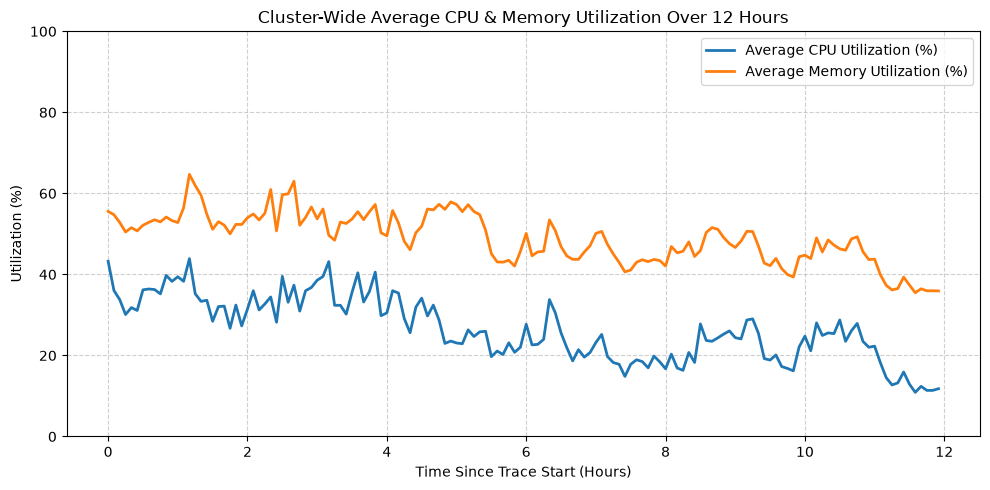

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

col_names = [
    'timestamp',
    'machine_id',
    'util_cpu',
    'util_mem',
    'util_disk',
    'load1',
    'load5',
    'load15',
]
df = pd.read_csv('data/server_usage.csv', names=col_names)

# 將時間戳記（秒）轉換成相對小時數，方便觀察 12 小時變化
df['hour'] = (df['timestamp'] - df['timestamp'].min()) / 3600.0

# 計算每個時間點（每 5 分鐘）所有機器的平均 CPU 與記憶體使用率
time_trend = df.groupby('hour')[['util_cpu', 'util_mem']].mean().reset_index()

# 繪製時間序列折線圖
plt.figure(figsize=(10, 5))
plt.plot(
    time_trend['hour'],
    time_trend['util_cpu'],
    label='Average CPU Utilization (%)',
    linewidth=2,
)
plt.plot(
    time_trend['hour'],
    time_trend['util_mem'],
    label='Average Memory Utilization (%)',
    linewidth=2,
)

plt.title('Cluster-Wide Average CPU & Memory Utilization Over 12 Hours')
plt.xlabel('Time Since Trace Start (Hours)')
plt.ylabel('Utilization (%)')
plt.ylim(0, 100)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig('week1_cluster_trend.png', dpi=300)
plt.show()